# Import Data From Excel

In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
import os
data_path = '../data/events.xlsx' if os.path.exists('../data/events.xlsx') else 'events.xlsx'
df = pd.read_excel(data_path)
df.head()


,event_id,user_id,event_name,event_time,session_id,device_type,product_id
0,1,1,app_opened,2026-01-01 09:00:00,S-1-D0,Android,NaN
1,2,1,product_viewed,2026-01-01 09:05:00,S-1-D0,Android,1.0
2,3,1,add_to_cart,2026-01-01 09:10:00,S-1-D0,Android,1.0
3,4,1,checkout_started,2026-01-01 09:15:00,S-1-D0,Android,1.0
4,5,1,purchase_completed,2026-01-01 09:20:00,S-1-D0,Android,1.0
...,...,...,...,...,...,...,...
39445,39446,2500,app_opened,2026-07-09 16:00:00,S-2500-D30,Android,NaN
39446,39447,2500,product_viewed,2026-07-09 16:04:00,S-2500-D30,Android,10.0
39447,39448,2500,add_to_cart,2026-07-09 16:09:00,S-2500-D30,Android,10.0
39448,39449,2500,checkout_started,2026-07-09 16:14:00,S-2500-D30,Android,10.0


In [3]:
df.drop_duplicates()


<bound method DataFrame.drop_duplicates of        event_id  user_id          event_name          event_time  session_id  \
0             1        1          app_opened 2026-01-01 09:00:00      S-1-D0   
1             2        1      product_viewed 2026-01-01 09:05:00      S-1-D0   
2             3        1         add_to_cart 2026-01-01 09:10:00      S-1-D0   
3             4        1    checkout_started 2026-01-01 09:15:00      S-1-D0   
4             5        1  purchase_completed 2026-01-01 09:20:00      S-1-D0   
...         ...      ...                 ...                 ...         ...   
39445     39446     2500          app_opened 2026-07-09 16:00:00  S-2500-D30   
39446     39447     2500      product_viewed 2026-07-09 16:04:00  S-2500-D30   
39447     39448     2500         add_to_cart 2026-07-09 16:09:00  S-2500-D30   
39448     39449     2500    checkout_started 2026-07-09 16:14:00  S-2500-D30   
39449     39450     2500  purchase_completed 2026-07-09 16:19:00  S-2500-D30 

In [4]:
df.describe()


<bound method NDFrame.describe of        event_id  user_id          event_name          event_time  session_id  \
0             1        1          app_opened 2026-01-01 09:00:00      S-1-D0   
1             2        1      product_viewed 2026-01-01 09:05:00      S-1-D0   
2             3        1         add_to_cart 2026-01-01 09:10:00      S-1-D0   
3             4        1    checkout_started 2026-01-01 09:15:00      S-1-D0   
4             5        1  purchase_completed 2026-01-01 09:20:00      S-1-D0   
...         ...      ...                 ...                 ...         ...   
39445     39446     2500          app_opened 2026-07-09 16:00:00  S-2500-D30   
39446     39447     2500      product_viewed 2026-07-09 16:04:00  S-2500-D30   
39447     39448     2500         add_to_cart 2026-07-09 16:09:00  S-2500-D30   
39448     39449     2500    checkout_started 2026-07-09 16:14:00  S-2500-D30   
39449     39450     2500  purchase_completed 2026-07-09 16:19:00  S-2500-D30   

     

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39450 entries, 0 to 39449
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   event_id     39450 non-null  int64         
 1   user_id      39450 non-null  int64         
 2   event_name   39450 non-null  str           
 3   event_time   39450 non-null  datetime64[us]
 4   session_id   39450 non-null  str           
 5   device_type  39450 non-null  str           
 6   product_id   28125 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(2), str(3)
memory usage: 3.1 MB


## Monthly Cohort Analysis

#### 1- Detecting usre's first time

In [6]:
user_first_time = df[df['event_name']=='app_opened'].groupby('user_id')['event_time'].min().sort_values(ascending = True).reset_index()

In [7]:
#renaming column
user_first_time.rename(columns = {'event_time':'first_time'}, inplace = True)
user_first_time

,user_id,first_time
0,1,2026-01-01 09:00:00
1,721,2026-01-01 09:00:00
2,901,2026-01-01 09:00:00
3,361,2026-01-01 09:00:00
4,1081,2026-01-01 09:00:00
...,...,...
2495,1800,2026-06-29 09:00:00
2496,2340,2026-06-29 09:00:00
2497,1260,2026-06-29 09:00:00
2498,1620,2026-06-29 09:00:00


#### 2- Detecting cohort month

In [8]:
user_first_time['cohort_month']=(
user_first_time['first_time'].dt.to_period('M'))
user_first_time

,user_id,first_time,cohort_month
0,1,2026-01-01 09:00:00,2026-01
1,721,2026-01-01 09:00:00,2026-01
2,901,2026-01-01 09:00:00,2026-01
3,361,2026-01-01 09:00:00,2026-01
4,1081,2026-01-01 09:00:00,2026-01
...,...,...,...
2495,1800,2026-06-29 09:00:00,2026-06
2496,2340,2026-06-29 09:00:00,2026-06
2497,1260,2026-06-29 09:00:00,2026-06
2498,1620,2026-06-29 09:00:00,2026-06


#### 3- Detecting monthly activity

In [9]:
monthly_activity = df[['user_id','event_time']]

In [10]:
monthly_activity['activity_month'] = (
    monthly_activity['event_time'].dt.to_period('M')
)
monthly_activity

,user_id,event_time,activity_month
0,1,2026-01-01 09:00:00,2026-01
1,1,2026-01-01 09:05:00,2026-01
2,1,2026-01-01 09:10:00,2026-01
3,1,2026-01-01 09:15:00,2026-01
4,1,2026-01-01 09:20:00,2026-01
...,...,...,...
39445,2500,2026-07-09 16:00:00,2026-07
39446,2500,2026-07-09 16:04:00,2026-07
39447,2500,2026-07-09 16:09:00,2026-07
39448,2500,2026-07-09 16:14:00,2026-07


In [11]:
monthly_activity = monthly_activity[['user_id','activity_month']].drop_duplicates()

In [12]:
monthly_activity

,user_id,activity_month
0,1,2026-01
5,2,2026-01
10,3,2026-01
14,4,2026-01
18,5,2026-01
...,...,...
39398,2496,2026-07
39406,2497,2026-07
39418,2498,2026-07
39428,2499,2026-07


### 4- Linking the cohort to the activity

In [13]:
cohort_data= user_first_time.merge(
monthly_activity[['user_id','activity_month']],
on = 'user_id',
how= 'inner')
cohort_data

,user_id,first_time,cohort_month,activity_month
0,1,2026-01-01 09:00:00,2026-01,2026-01
1,721,2026-01-01 09:00:00,2026-01,2026-01
2,721,2026-01-01 09:00:00,2026-01,2026-03
3,901,2026-01-01 09:00:00,2026-01,2026-01
4,361,2026-01-01 09:00:00,2026-01,2026-01
...,...,...,...,...
5381,1620,2026-06-29 09:00:00,2026-06,2026-06
5382,1620,2026-06-29 09:00:00,2026-06,2026-07
5383,1620,2026-06-29 09:00:00,2026-06,2026-08
5384,900,2026-06-29 09:00:00,2026-06,2026-06


### 5- Calculate period number

In [14]:
cohort_data['period_number']=(
    (cohort_data['activity_month'].dt.year -
    cohort_data['cohort_month'].dt.year)*12
    +
    (cohort_data['activity_month'].dt.month -
    cohort_data['cohort_month'].dt.month)
)
cohort_data

,user_id,first_time,cohort_month,activity_month,period_number
0,1,2026-01-01 09:00:00,2026-01,2026-01,0
1,721,2026-01-01 09:00:00,2026-01,2026-01,0
2,721,2026-01-01 09:00:00,2026-01,2026-03,2
3,901,2026-01-01 09:00:00,2026-01,2026-01,0
4,361,2026-01-01 09:00:00,2026-01,2026-01,0
...,...,...,...,...,...
5381,1620,2026-06-29 09:00:00,2026-06,2026-06,0
5382,1620,2026-06-29 09:00:00,2026-06,2026-07,1
5383,1620,2026-06-29 09:00:00,2026-06,2026-08,2
5384,900,2026-06-29 09:00:00,2026-06,2026-06,0


### 6- Calculating the number of users in each period


In [15]:
retention_count=(
cohort_data.groupby(['cohort_month','period_number'])['user_id'].nunique().reset_index(name='active_users'))
retention_count

,cohort_month,period_number,active_users
0,2026-01,0,434
1,2026-01,1,247
2,2026-01,2,162
3,2026-01,3,86
4,2026-01,4,3
5,2026-02,0,392
6,2026-02,1,247
7,2026-02,2,134
8,2026-02,3,78
9,2026-03,0,434


### 7-Calculating the size of each cohort

In [16]:
cohort_size=(
    user_first_time.groupby('cohort_month')['user_id'].nunique().reset_index(name='cohort_users')
)
cohort_size

,cohort_month,cohort_users
0,2026-01,434
1,2026-02,392
2,2026-03,434
3,2026-04,420
4,2026-05,434
5,2026-06,386


### Creating a Cohort Matrix

In [17]:
retention_matrix=(
    retention_count.pivot(
        index='cohort_month',
        columns='period_number',
        values='active_users'
    )
)
retention_matrix

period_number,0,1,2,3,4
cohort_month,,,,,
2026-01,434.0,247.0,162.0,86.0,3.0
2026-02,392.0,247.0,134.0,78.0,NaN
2026-03,434.0,260.0,155.0,82.0,NaN
2026-04,420.0,266.0,143.0,81.0,NaN
2026-05,434.0,262.0,154.0,81.0,NaN
2026-06,386.0,245.0,129.0,71.0,NaN


### Calculating retention rates

In [18]:
retention_rate=(
    retention_matrix
    .div(
        cohort_size.set_index('cohort_month')['cohort_users'],axis=0
    )*100
).round(2)

In [19]:
retention_rate

period_number,0,1,2,3,4
cohort_month,,,,,
2026-01,100.0,56.91,37.33,19.82,0.69
2026-02,100.0,63.01,34.18,19.90,NaN
2026-03,100.0,59.91,35.71,18.89,NaN
2026-04,100.0,63.33,34.05,19.29,NaN
2026-05,100.0,60.37,35.48,18.66,NaN
2026-06,100.0,63.47,33.42,18.39,NaN


In [36]:
# Formating the percentages
annot_matrix= retention_rate.map(
    lambda x: f"{x:.1f}%" if pd.notnull(x) else ""
)
annot_matrix

period_number,0,1,2,3,4
cohort_month,,,,,
2026-01,100.0%,56.9%,37.3%,19.8%,0.7%
2026-02,100.0%,63.0%,34.2%,19.9%,
2026-03,100.0%,59.9%,35.7%,18.9%,
2026-04,100.0%,63.3%,34.0%,19.3%,
2026-05,100.0%,60.4%,35.5%,18.7%,
2026-06,100.0%,63.5%,33.4%,18.4%,


In [21]:
retention_rate

period_number,0,1,2,3,4
cohort_month,,,,,
2026-01,100.0,56.91,37.33,19.82,0.69
2026-02,100.0,63.01,34.18,19.90,NaN
2026-03,100.0,59.91,35.71,18.89,NaN
2026-04,100.0,63.33,34.05,19.29,NaN
2026-05,100.0,60.37,35.48,18.66,NaN
2026-06,100.0,63.47,33.42,18.39,NaN


## Visualize 

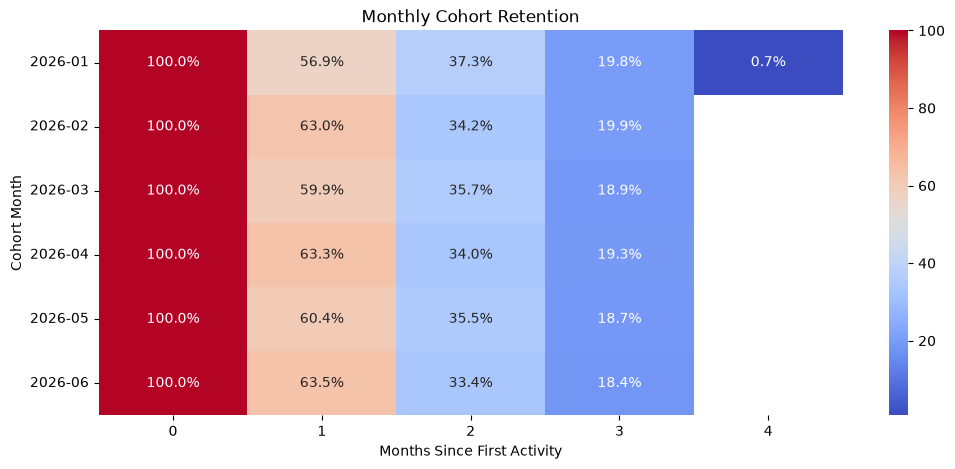

In [35]:

plt.figure(figsize=(12,5))
plt.title('Cohort Analysis')
sns.heatmap(
    data=retention_rate,
    annot=annot_matrix,
    cmap='coolwarm',
    fmt="",
)
plt.title('Monthly Cohort Retention')
plt.xlabel('Months Since First Activity')
plt.ylabel('Cohort Month')
plt.yticks(rotation=0)
plt.show()